# 07 · Adstock + saturation MMM: training, comparison & evaluation
**Team 2 – Marketing Mix Modelling**

The model ladder (each step adds one idea to the previous one):

| # | Model | Carryover (adstock) | Diminishing returns (saturation) | Media effects ≥ 0 | Ridge |
|---|---|---|---|---|---|
| M0 | Baseline OLS (all controls) | – | – | – | – |
| M1 | Linear, constrained | – | – | ✓ | ✓ |
| M2 | Adstock | ✓ | – | ✓ | ✓ |
| M3 | **Adstock + saturation (final)** | ✓ | ✓ | ✓ | ✓ |

**How the final model works**, for each channel *c* and month *t*:
1. **Adstock:** `a_t = x_t + λ_c · a_{t-1}`, rescaled by `(1-λ_c)`. A share λ of the effect carries into the next month. λ is limited to a plausible range for each channel type (e.g. TV 0.3–0.8, Search 0–0.3).
2. **Saturation (Hill curve):** `h_t = s/(s + K_c)` with `s = a_t / mean spend`. Revenue grows with spend but each extra LKR adds less. `K_c` is the spend level (as a multiple of average spend) where the channel reaches half of its maximum effect.
3. **Regression:** `revenue_t = base + Σ β_c·h_ct + Σ γ_k·control_kt + ε`, with **β_c ≥ 0** and a ridge penalty.

λ, K and the ridge strength are **hyperparameters**. They are chosen by differential evolution (SciPy) to minimise **rolling-origin CV error on the 30 training months only**. The 6 test months are used once, at the end.


In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.mmm_core import *
from src import mmm_plot_style as ps; ps.apply()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG, TAB, MOD = ROOT/"reports/figures", ROOT/"outputs/mmm", ROOT/"models/mmm"
for d in (FIG, TAB, MOD): d.mkdir(parents=True, exist_ok=True)

# ---- Inputs from Team 1 (Data Engineering & EDA) ----
DATA_PATH = ROOT / "data" / "processed" / "mmm_analysis_ready.csv"
SPLIT = json.load(open(ROOT / "data" / "processed" / "split_info.json"))
TRAIN_END = SPLIT["train_end"]   # documented chronological split (train 2023-01..2025-06, test 2025-07..2025-12)
LAB = CHANNEL_LABELS
df = load_data(DATA_PATH)
train, test = df[df.month <= TRAIN_END].reset_index(drop=True), df[df.month > TRAIN_END].reset_index(drop=True)
print(f"{len(df)} months | train {train.month.min():%Y-%m} → {train.month.max():%Y-%m} ({len(train)}) | test {test.month.min():%Y-%m} → {test.month.max():%Y-%m} ({len(test)})")

36 months | train 2023-01 → 2025-06 (30) | test 2025-07 → 2025-12 (6)


In [2]:
import time, joblib
SEARCH = dict(maxiter=40, popsize=10)   # differential-evolution budget (raise for a final run if time allows)
results, models = {}, {}

def evaluate(name, model, info=None):
    tr_pred, te_pred = model.predict(train), model.predict(test)
    r = {"train R2": metrics(train[TARGET], tr_pred)["R2"],
         "CV RMSE": (info or {}).get("cv_rmse", cv_rmse(model, train)),
         **{f"test {k}": v for k, v in metrics(test[TARGET], te_pred).items()}}
    model.fit(train)  # cv_rmse refits on folds; restore the full-train fit
    results[name], models[name] = r, model
    return r

## 1. Train the model ladder

In [3]:
t0 = time.time()
evaluate("M0 Baseline OLS (all controls)", MMM(use_adstock=False, use_saturation=False, nonneg_media=False, controls=ALL_CONTROLS).fit(train))
m, info = tune_mmm(train, use_adstock=False, use_saturation=False, **SEARCH);  evaluate("M1 Linear, constrained + ridge", m, info)
m, info = tune_mmm(train, use_adstock=True,  use_saturation=False, **SEARCH);  evaluate("M2 Adstock", m, info)
m, info = tune_mmm(train, use_adstock=True,  use_saturation=True,  **SEARCH);  evaluate("M3 Adstock + saturation", m, info); final_info = info
print(f"trained in {time.time()-t0:.0f}s")

trained in 161s


## 2. Sensitivity variants of M3
Same structure, one change each. These confirm (or overturn) the choices of controls and curve shape.

In [4]:
t0 = time.time()
m, info = tune_mmm(train, controls=CONTROLS + ["average_price_index"], **SEARCH); evaluate("M3a + price index", m, info)
m, info = tune_mmm(train, controls=ALL_CONTROLS, **SEARCH);                       evaluate("M3b all 6 controls", m, info)
m, info = tune_mmm(train, alpha=None, **SEARCH);                                  evaluate("M3c S-shaped curve (alpha tuned)", m, info)
print(f"trained in {time.time()-t0:.0f}s")

trained in 426s


In [5]:
comp = pd.DataFrame(results).T
show = comp.copy()
for c in ["CV RMSE", "test RMSE", "test MAE"]: show[c] = show[c] / 1e6
show = show.rename(columns={"CV RMSE": "CV RMSE (M)", "test RMSE": "test RMSE (M)", "test MAE": "test MAE (M)"})
comp.to_csv(TAB / "07_model_comparison.csv")
show.round(3)

,train R2,CV RMSE (M),test RMSE (M),test MAE (M),test MAPE_%,test R2
M0 Baseline OLS (all controls),0.853,6.379,3.480,2.972,3.393,0.554
"M1 Linear, constrained + ridge",0.690,3.209,2.505,2.425,2.751,0.769
M2 Adstock,0.709,3.092,1.980,1.853,2.093,0.856
M3 Adstock + saturation,0.713,3.077,2.043,1.901,2.139,0.846
M3a + price index,0.709,2.956,1.750,1.563,1.769,0.887
M3b all 6 controls,0.696,2.965,1.993,1.895,2.152,0.854
M3c S-shaped curve (alpha tuned),0.713,3.014,2.131,1.966,2.209,0.833


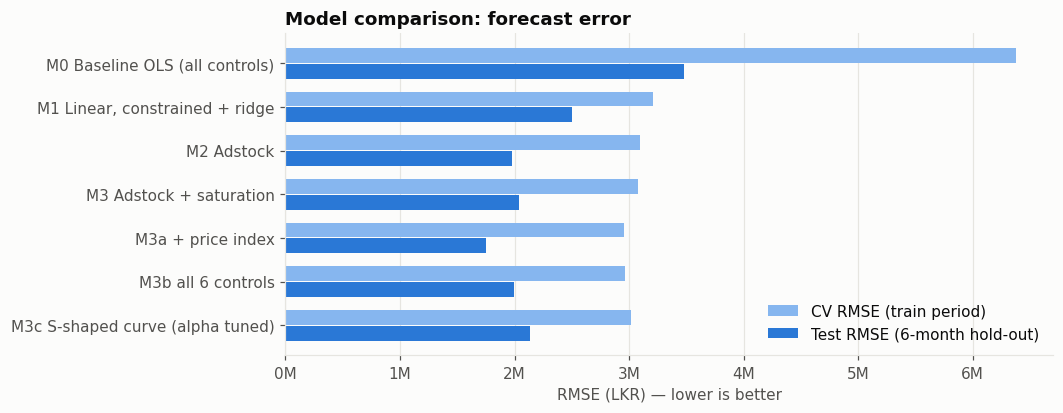

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8))
order = list(comp.index)[::-1]
y = np.arange(len(order))
ax.barh(y + 0.18, comp.loc[order, "CV RMSE"], height=0.34, color="#86b6ef", label="CV RMSE (train period)")
ax.barh(y - 0.18, comp.loc[order, "test RMSE"], height=0.34, color="#2a78d6", label="Test RMSE (6-month hold-out)")
ax.set_yticks(y, order); ps.millions(ax, "x"); ax.set_xlabel("RMSE (LKR) — lower is better")
ax.legend(loc="lower right"); ax.set_title("Model comparison: forecast error"); ax.grid(axis="y", visible=False)
fig.savefig(FIG / "07_model_comparison.png"); plt.show()

## 3. Choose the final model
The rule set before seeing test results: **lowest CV RMSE among the M3 family**. If a variant beats M3 by less than 2%, keep the simpler M3, because its effects are easier to interpret and it has fewer things to go wrong.

In [7]:
fam = comp.loc[[i for i in comp.index if i.startswith("M3")], "CV RMSE"]
best = fam.idxmin()
FINAL_NAME = best if fam[best] < 0.98 * fam["M3 Adstock + saturation"] else "M3 Adstock + saturation"
final = models[FINAL_NAME]
print("Final model:", FINAL_NAME)
print("controls:", final.controls)
hp = pd.DataFrame({"adstock λ": final.lam, "half-life (months)": {c: (np.log(.5)/np.log(l) if l > 0.01 else 0) for c, l in final.lam.items()},
                   "Hill K (× mean spend)": final.K, "Hill alpha": final.alpha}).rename(index=LAB)
print(f"ridge = {final.ridge:.3f}")
hp.round(3)

Final model: M3a + price index
controls: ['promotion_discount_pct', 'seasonal_demand_index', 'competitor_pressure_index_0_100', 'economic_sentiment_index_0_100', 'average_price_index']
ridge = 0.776


,adstock λ,half-life (months),Hill K (× mean spend),Hill alpha
TV,0.302,0.580,1.114,1.000
Facebook/Instagram,0.076,0.269,1.415,1.000
Google Search,0.000,0.000,0.522,1.000
YouTube,0.111,0.315,0.500,1.000
Radio,0.224,0.463,0.576,1.000
Outdoor,0.376,0.708,0.507,1.000


**Result:** adding the price index lowers CV error by about 4% (more than the 2% threshold) and also gives the best hold-out accuracy, so it is **kept as a control** in the final model. It is there to absorb price-level and inflation effects (it is collinear with inflation and time). Its coefficient should not be read as a causal price elasticity. Its job is to stop media from being credited for price-driven revenue changes. Holidays (M3b) and an S-shaped curve (M3c) do not beat the threshold, so the simpler choices stay. Carryover is short for every channel (half-life under one month), which is plausible for an FMCG category with monthly data.


## 4. Hold-out fit: actual vs predicted

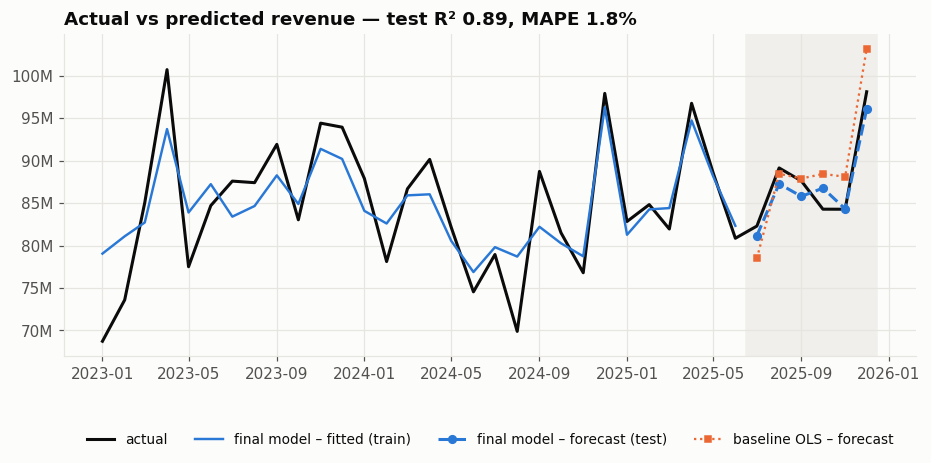

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(df.month, df[TARGET], color=ps.ACTUAL_COLOR, label="actual")
ax.plot(train.month, final.predict(train), color=ps.PRED_COLOR, lw=1.6, label="final model – fitted (train)")
ax.plot(test.month, final.predict(test), color=ps.PRED_COLOR, lw=2, ls="--", marker="o", ms=5, label="final model – forecast (test)")
ax.plot(test.month, models["M0 Baseline OLS (all controls)"].predict(test), color="#eb6834", lw=1.5, ls=":", marker="s", ms=4, label="baseline OLS – forecast")
ax.axvspan(test.month.min() - pd.Timedelta(days=15), test.month.max() + pd.Timedelta(days=15), color="#f0efec", zorder=0)
ps.millions(ax); ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), ncol=4, fontsize=9)
r = results[FINAL_NAME]
ax.set_title(f"Actual vs predicted revenue — test R² {r['test R2']:.2f}, MAPE {r['test MAPE_%']:.1f}%")
fig.savefig(FIG / "07_actual_vs_predicted.png"); plt.show()

## 5. Residual diagnostics (training period)
Regression assumes errors are unpatterned. We check autocorrelation (Durbin-Watson ≈ 2 is ideal, and the Ljung-Box p-value should be > 0.05), normality (Shapiro-Wilk p > 0.05) and heteroscedasticity (Breusch-Pagan p > 0.05).

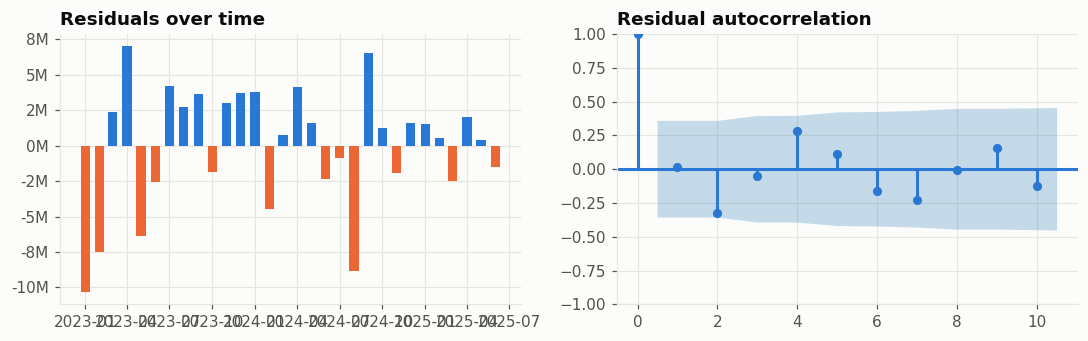

,value
Durbin-Watson,1.762
Ljung-Box p (lag 3),0.287
Shapiro-Wilk p,0.125
Breusch-Pagan p,0.228
residual mean (LKR),0.000
residual std (LKR),"4,216,904.706"


In [9]:
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from scipy.stats import shapiro
res = train[TARGET].values - final.predict(train)
import statsmodels.api as sm
bp = het_breuschpagan(res, sm.add_constant(final.predict(train)))
diag = pd.Series({"Durbin-Watson": durbin_watson(res),
                  "Ljung-Box p (lag 3)": acorr_ljungbox(res, lags=[3]).lb_pvalue.iloc[0],
                  "Shapiro-Wilk p": shapiro(res).pvalue,
                  "Breusch-Pagan p": bp[1],
                  "residual mean (LKR)": res.mean(), "residual std (LKR)": res.std()}, name="value")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].bar(train.month, res, width=20, color=["#2a78d6" if v >= 0 else "#eb6834" for v in res]); ps.millions(axs[0]); axs[0].set_title("Residuals over time")
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(res, lags=10, ax=axs[1], color=ps.PRED_COLOR, vlines_kwargs={"colors": ps.PRED_COLOR}); axs[1].set_title("Residual autocorrelation")
fig.tight_layout(); fig.savefig(FIG / "07_residuals.png"); plt.show()
diag.to_frame().round(3)

## 6. Reliability check 1: does the search land in the same place with a different random seed?
Differential evolution is stochastic. If two seeds give very different channel effects, those effects are not well identified by the data.

In [10]:
seed_rows = {}
for seed in [1, 2]:
    m, info = tune_mmm(train, controls=final.controls, alpha=final.alpha[CHANNELS[0]] if FINAL_NAME != "M3c S-shaped curve (alpha tuned)" else None, seed=seed, **SEARCH)
    seed_rows[f"seed {seed}"] = m
seed_rows["seed 0 (final)"] = final
def roas(m, d):
    c = m.contributions(d)[CHANNELS].sum(); return (c / d[CHANNELS].sum()).rename(index=LAB)
stab = pd.DataFrame({k: roas(m, train) for k, m in seed_rows.items()})
stab["CV RMSE seed (M)"] = np.nan
print("CV RMSE by seed:", {k: round(cv_rmse(m, train)/1e6, 3) for k, m in seed_rows.items()}); final.fit(train)
stab.drop(columns="CV RMSE seed (M)").round(2).rename_axis("training-period ROAS")

CV RMSE by seed: {'seed 1': 2.957, 'seed 2': 2.955, 'seed 0 (final)': 2.956}


,seed 1,seed 2,seed 0 (final)
training-period ROAS,,,
TV,0.900,0.850,1.020
Facebook/Instagram,0.500,0.490,0.540
Google Search,4.660,4.580,4.630
YouTube,3.980,4.290,4.370
Radio,0.000,0.000,0.000
Outdoor,6.710,6.190,6.420


## 7. Refit the final model on all 36 months
Hyperparameters (λ, K, ridge) stay fixed at the values chosen on the training period. Only the regression coefficients are re-estimated using all 36 months. The test set has done its job of validating the *method*. The final coefficients should use all the data, and these are the ones handed to the ROI, Optimisation and Dashboard teams.

In [11]:
final_full = MMM(lam=final.lam, K=final.K, alpha=final.alpha, ridge=final.ridge, controls=final.controls).fit(df)
full_fit = metrics(df[TARGET], final_full.predict(df))
print("Full-data fit:", {k: round(v, 3) for k, v in full_fit.items()})

params = final_full.to_dict()
params.update({
    "model_name": FINAL_NAME, "fit_period": f"{df.month.min():%Y-%m} to {df.month.max():%Y-%m}",
    "hyperparameters_tuned_on": f"{train.month.min():%Y-%m} to {train.month.max():%Y-%m} (rolling-origin CV)",
    "holdout_metrics": {k: float(v) for k, v in results[FINAL_NAME].items()},
    "current_monthly_spend": {c: float(df[df.month.dt.year == df.month.dt.year.max()][c].mean()) for c in CHANNELS},
    "current_spend_definition": "average monthly spend in the latest year (2025)",
})
import json
json.dump(params, open(MOD / "final_mmm.json", "w"), indent=2)
final.save_json(MOD / "final_mmm_train_only.json")
joblib.dump({"final_full": final_full, "final_train": final, "ladder": models}, MOD / "mmm_models.pkl")
print("saved: final_mmm.json, final_mmm_train_only.json, mmm_models.pkl, 02_model_comparison.csv")

Full-data fit: {'RMSE': 3971414.892, 'MAE': 3082122.051, 'MAPE_%': 3.757, 'R2': 0.722}
saved: final_mmm.json, final_mmm_train_only.json, mmm_models.pkl, 02_model_comparison.csv
